# The models: first attempts, what improved them, and what a form can see

Sam Strickler · Honors research project · Home Credit Default Risk (Kaggle)

1. **First models.** Six kinds of model, tuned and compared. Best test AUC: 0.7786.
2. **What improved the model.** The pipeline rebuilt one change at a time. Test AUC: 0.7976.
3. **Fairness, and what the form can see.** Why the website uses a smaller model, trained
   only on form answers and without sex or marital status.

Run 01_eda.ipynb first. It saves the table this notebook loads. Sections 2 and 3 took hours
to compute, so their cells load saved results from `results/`. 03_train.ipynb builds the
model the site serves.

**AUC** is the score used throughout. Take one applicant who missed a payment and one who
didn't. AUC is the chance the model rates the first one as riskier. 0.5 is a coin flip, 1.0
is perfect, and credit models usually land between 0.70 and 0.80.

In [ ]:
import json
import os

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from optuna.integration.mlflow import MLflowCallback
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report,
                             precision_recall_curve, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedShuffleSplit,
                                     cross_val_score, train_test_split)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

import features

# Earth palette, shared with the website
earth_palette = [
    "#6b8f71",  # sage green
    "#8b5a2b",  # warm brown
    "#3b5c8a",  # muted deep blue
    "#e0b44c",  # warm earthy yellow
    "#8c2b2b",  # dark red
]
sns.set_theme(
    style="whitegrid",
    rc={
        "axes.facecolor": "#f2ede6",
        "figure.facecolor": "#f2ede6",
        "axes.edgecolor": "#3b342b",
        "grid.color": "#d0c4b4",
        "axes.labelcolor": "#222222",
        "xtick.color": "#222222",
        "ytick.color": "#222222",
    },
)
sns.set_palette(earth_palette)

In [ ]:
# Written by 01_eda.ipynb: renamed columns, auxiliary aggregates merged, empty columns dropped
df = pd.read_parquet("cache/applications.parquet")
df.shape

---

# 1. First models

A first pass, done the usual way: fill in missing values, scale, one-hot encode, then try
six kinds of model. Section 2 finds out which of these choices helped and which hurt.

## 1.1 Preprocessing

In [24]:
X = df.drop(columns=["Default"])
y = df["Default"]

# Split before any preprocessing, stratified to keep the 8% default rate in both halves
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [25]:
num_cols = X_train.select_dtypes(include=np.number).columns
cat_cols = X_train.select_dtypes(include=["object", "category", "bool", "string"]).columns

print("Numeric:", list(num_cols))
print("Categorical:", list(cat_cols))

Numeric: ['Children', 'Income', 'Credit Amount', 'Annuity', 'Goods Price', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'Family Members', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'External Score 1', 'External Score 2', 'External Score 3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BEGINEXPLUATATION_MODE', 'YEARS_BUILD_MODE', 'COMMONA

In [26]:
# Missingness is heavy, so both column types are imputed before scaling / encoding
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols),
])

## 1.2 Compare models with cross-validation

Every model gets the same preprocessing, so differences come from the model. To keep the
searches quick they run on a 20,000-row sample of the training split and score by average
precision.

In [27]:
# Log every search and test run to a local MLflow database. The URI is built from the
# absolute path because MLflow's default mangles the spaces in this folder's name.
mlflow.set_tracking_uri(f"sqlite:///{os.path.abspath('mlflow.db')}")
mlflow.set_experiment("home-credit-default-risk")


def pipeline(model):
    return Pipeline([("preprocessor", preprocessor), ("model", model)])


def xgb_model(**params):
    return XGBClassifier(tree_method="auto", eval_metric="aucpr", objective="binary:logistic", **params)


def lgbm_model(**params):
    # LightGBM ignores `subsample` unless bagging is switched on with subsample_freq
    return LGBMClassifier(objective="binary", subsample_freq=1, verbosity=-1, **params)


def catboost_model(**params):
    # Bernoulli bootstrap is what makes `subsample` a valid parameter
    return CatBoostClassifier(bootstrap_type="Bernoulli", verbose=False, allow_writing_files=False, **params)


lr_clf = pipeline(LogisticRegression(class_weight={0: 1.0, 1: 2.4}, max_iter=1000))
xgb_clf = pipeline(xgb_model())
nn_clf = pipeline(MLPClassifier(max_iter=400, solver="adam"))

In [28]:
# 20,000 rows, stratified; expressed as a test fraction, the way the searches were run
sss = StratifiedShuffleSplit(n_splits=1, test_size=(len(X_train) - 20_000) / len(X_train), random_state=42)
tune_idx, _ = next(sss.split(X_train, y_train))
X_tune, y_tune = X_train.iloc[tune_idx], y_train.iloc[tune_idx]

### Logistic regression

In [29]:
param_grid_lr = {
    "model__C": [0.1, 1, 10],  # smaller C = stronger regularization
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"],
}

grid_lr = GridSearchCV(lr_clf, param_grid_lr, scoring="average_precision", cv=5)
grid_lr.fit(X_tune, y_tune)
print("Best LR params:", grid_lr.best_params_)
print("Best LR CV score:", grid_lr.best_score_)

Best LR params: {'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Best LR CV score: 0.22342497718107796


### XGBoost, grid search

In [30]:
param_grid_xgb = {
    "model__max_depth": [2, 3, 5],
    "model__n_estimators": [200, 400],
    "model__learning_rate": [0.001, 0.02, 0.05],
    "model__scale_pos_weight": [3, 6, 11],  # roughly 1/4, 1/2 and 1x the negative:positive ratio
}

grid_xgb = GridSearchCV(xgb_clf, param_grid_xgb, scoring="average_precision", cv=5)
grid_xgb.fit(X_tune, y_tune)
print("Best XGB params:", grid_xgb.best_params_)
print("Best XGB CV score:", grid_xgb.best_score_)

Best XGB params: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 400, 'model__scale_pos_weight': 3}
Best XGB CV score: 0.23658004948694605


### XGBoost with Optuna

The grid above only tries 54 combinations. Optuna searches a wider range and spends its
trials where they are paying off.

In [31]:
optuna.logging.set_verbosity(optuna.logging.WARNING)


def cv_average_precision(model):
    return cross_val_score(model, X_tune, y_tune, scoring="average_precision", cv=5).mean()


def run_search(run_name, label, objective, n_trials=40):
    """Optuna search maximising CV average precision, logged to MLflow."""
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
    callback = MLflowCallback(tracking_uri=mlflow.get_tracking_uri(), metric_name="avg_precision",
                              create_experiment=False, mlflow_kwargs={"nested": True})
    with mlflow.start_run(run_name=run_name):
        study.optimize(objective, n_trials=n_trials, show_progress_bar=True, callbacks=[callback])
        mlflow.log_params(study.best_params)
        mlflow.log_metric("best_cv_avg_precision", study.best_value)
    print(f"Best {label} params:", study.best_params)
    print(f"Best {label} CV score:", study.best_value)
    return study


def objective(trial):
    return cv_average_precision(pipeline(xgb_model(
        max_depth=trial.suggest_int("max_depth", 2, 8),
        n_estimators=trial.suggest_int("n_estimators", 100, 600),
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 1, 12),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    )))


study = run_search("xgb_optuna_search", "Optuna XGB", objective)

Best Optuna XGB params: {'max_depth': 4, 'n_estimators': 293, 'learning_rate': 0.03283130170288954, 'scale_pos_weight': 3.7480682572931348, 'subsample': 0.7237093364189056, 'colsample_bytree': 0.7636004284281295, 'min_child_weight': 6, 'reg_alpha': 0.057439331639992375, 'reg_lambda': 9.44867998440012}
Best Optuna XGB CV score: 0.2477391313362837


### LightGBM with Optuna

The same search as XGBoost.

In [33]:
def objective_lgbm(trial):
    return cv_average_precision(pipeline(lgbm_model(
        num_leaves=trial.suggest_int("num_leaves", 8, 128),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        n_estimators=trial.suggest_int("n_estimators", 100, 600),
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 100),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 1, 12),
    )))


study_lgbm = run_search("lgbm_optuna_search", "LightGBM", objective_lgbm)

Best LightGBM params: {'num_leaves': 37, 'max_depth': 10, 'n_estimators': 362, 'learning_rate': 0.01158774243708483, 'min_child_samples': 52, 'subsample': 0.7000347085097536, 'colsample_bytree': 0.7390223118936016, 'reg_alpha': 0.4633992503362058, 'reg_lambda': 0.036337126717267146, 'scale_pos_weight': 3.9518352551878237}
Best LightGBM CV score: 0.2518277946134412


### CatBoost with Optuna

CatBoost can handle text categories by itself, but here it gets the same one-hot inputs as
the other models so the comparison stays fair.

In [34]:
def objective_catboost(trial):
    return cv_average_precision(pipeline(catboost_model(
        depth=trial.suggest_int("depth", 3, 10),
        iterations=trial.suggest_int("iterations", 100, 600),
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1e-3, 10, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        rsm=trial.suggest_float("rsm", 0.6, 1.0),  # CatBoost's colsample_bylevel
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 1, 12),
    )))


study_catboost = run_search("catboost_optuna_search", "CatBoost", objective_catboost)

Best CatBoost params: {'depth': 7, 'iterations': 486, 'learning_rate': 0.025556152459754355, 'l2_leaf_reg': 1.9332114161583103, 'subsample': 0.8505374744476087, 'rsm': 0.7696954281685016, 'scale_pos_weight': 4.77079217092948}
Best CatBoost CV score: 0.24193468853582684


### Neural network (multi-layer perceptron)

In [35]:
param_grid_nn = {
    "model__hidden_layer_sizes": [(64,), (64, 64)],  # one hidden layer vs two
    "model__alpha": [1e-4, 1e-3],
}

# 3 folds and 2 workers: the MLP is the slowest model here and the most memory-hungry
grid_nn = GridSearchCV(nn_clf, param_grid_nn, scoring="average_precision", cv=3,
                       n_jobs=2, pre_dispatch=2)
grid_nn.fit(X_tune, y_tune)
print("Best NN params:", grid_nn.best_params_)
print("Best NN CV score:", grid_nn.best_score_)

Best NN params: {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64,)}
Best NN CV score: 0.14978566900962287


## 1.3 Test evaluation

Each tuned model is refit on the full training split and scored on the test set.

In [36]:
models = {
    "logistic_regression": grid_lr.best_estimator_,
    "xgboost_gridsearch": grid_xgb.best_estimator_,
    "xgboost_optuna": pipeline(xgb_model(**study.best_params)),
    "lightgbm_optuna": pipeline(lgbm_model(**study_lgbm.best_params)),
    "catboost_optuna": pipeline(catboost_model(**study_catboost.best_params)),
    "neural_net": grid_nn.best_estimator_,
}

results = {}
for name, model in models.items():
    with mlflow.start_run(run_name=f"test_eval_{name}"):
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

        auc = roc_auc_score(y_test, y_proba)
        ap = average_precision_score(y_test, y_proba)
        results[name] = {"auc": auc, "ap": ap}

        params = model.named_steps["model"].get_params()
        mlflow.log_params({k: v for k, v in params.items() if v is None or isinstance(v, (int, float, str, bool))})
        mlflow.log_metric("test_auc", auc)
        mlflow.log_metric("test_avg_precision", ap)

        print(f"\n===== {name} =====")
        print("Classification report:")
        print(classification_report(y_test, y_pred))
        print(f"Test AUC: {auc:.3f}")
        print(f"Test Average Precision: {ap:.3f}")

# SHAP and threshold tuning below use the best model by test average precision
best_model_name = max(results, key=lambda name: results[name]["ap"])
best = results[best_model_name]
print(f"\nBest model by test Average Precision: {best_model_name} (AP={best['ap']:.3f}, AUC={best['auc']:.3f})")


===== logistic_regression =====
Classification report:
              precision    recall  f1-score   support

         0.0       0.93      0.98      0.95     56538
         1.0       0.38      0.15      0.22      4965

    accuracy                           0.91     61503
   macro avg       0.65      0.56      0.58     61503
weighted avg       0.88      0.91      0.89     61503

Test AUC: 0.767
Test Average Precision: 0.252



===== xgboost_gridsearch =====
Classification report:
              precision    recall  f1-score   support

         0.0       0.93      0.98      0.95     56538
         1.0       0.39      0.18      0.24      4965

    accuracy                           0.91     61503
   macro avg       0.66      0.58      0.60     61503
weighted avg       0.89      0.91      0.90     61503

Test AUC: 0.772
Test Average Precision: 0.264



===== xgboost_optuna =====
Classification report:
              precision    recall  f1-score   support

         0.0       0.94      0.95      0.95     56538
         1.0       0.34      0.27      0.30      4965

    accuracy                           0.90     61503
   macro avg       0.64      0.61      0.62     61503
weighted avg       0.89      0.90      0.89     61503

Test AUC: 0.776
Test Average Precision: 0.272



===== lightgbm_optuna =====
Classification report:
              precision    recall  f1-score   support

         0.0       0.94      0.95      0.94     56538
         1.0       0.33      0.27      0.30      4965

    accuracy                           0.90     61503
   macro avg       0.64      0.61      0.62     61503
weighted avg       0.89      0.90      0.89     61503

Test AUC: 0.776
Test Average Precision: 0.272



===== catboost_optuna =====
Classification report:
              precision    recall  f1-score   support

         0.0       0.94      0.93      0.93     56538
         1.0       0.30      0.36      0.33      4965

    accuracy                           0.88     61503
   macro avg       0.62      0.64      0.63     61503
weighted avg       0.89      0.88      0.89     61503

Test AUC: 0.779
Test Average Precision: 0.275



===== neural_net =====
Classification report:
              precision    recall  f1-score   support

         0.0       0.93      0.98      0.95     56538
         1.0       0.33      0.12      0.18      4965

    accuracy                           0.91     61503
   macro avg       0.63      0.55      0.56     61503
weighted avg       0.88      0.91      0.89     61503

Test AUC: 0.734
Test Average Precision: 0.211

Best model by test Average Precision: catboost_optuna (AP=0.275, AUC=0.779)


| model | test AUC | average precision |
|---|---|---|
| logistic regression | 0.767 | 0.252 |
| XGBoost, grid search | 0.772 | 0.264 |
| XGBoost, Optuna | 0.776 | 0.272 |
| LightGBM | 0.776 | 0.272 |
| **CatBoost** | **0.779** | **0.275** |
| neural network | 0.734 | 0.211 |

CatBoost comes out on top, but the three boosted-tree models are within 0.003 of each other,
which is less than the test set can tell apart (§2.1). The neural network got a much smaller
search than the others, so its last place says little about neural networks in general.

One flaw to keep in mind: the winner here and the cutoff in §1.5 were both picked on the
test set. Section 2 moves those choices to cross-validation.

## 1.4 Explaining the best model with SHAP

SHAP shows which features push a prediction up or down. Each dot is one of 3,000 test
applicants.

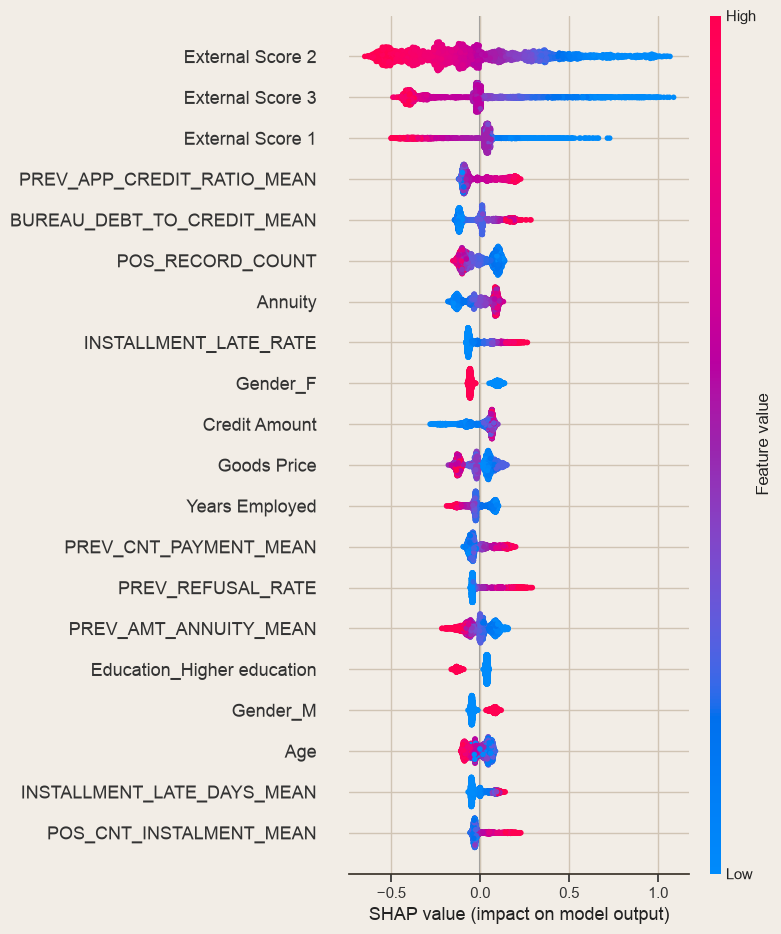

In [37]:
best_model = models[best_model_name]  # already fit on X_train above
fitted_preprocessor = best_model.named_steps["preprocessor"]
feature_names = [c.split("__", 1)[-1] for c in fitted_preprocessor.get_feature_names_out()]

sample_idx = np.random.RandomState(42).choice(len(X_test), size=3000, replace=False)
X_sample = fitted_preprocessor.transform(X_test.iloc[sample_idx])
if hasattr(X_sample, "toarray"):
    X_sample = X_sample.toarray()

shap_values = shap.TreeExplainer(best_model.named_steps["model"]).shap_values(X_sample)
if isinstance(shap_values, list):  # some binary classifiers return one array per class
    shap_values = shap_values[1]

shap.summary_plot(shap_values, X_sample, feature_names=feature_names, show=False)
plt.tight_layout()
plt.show()

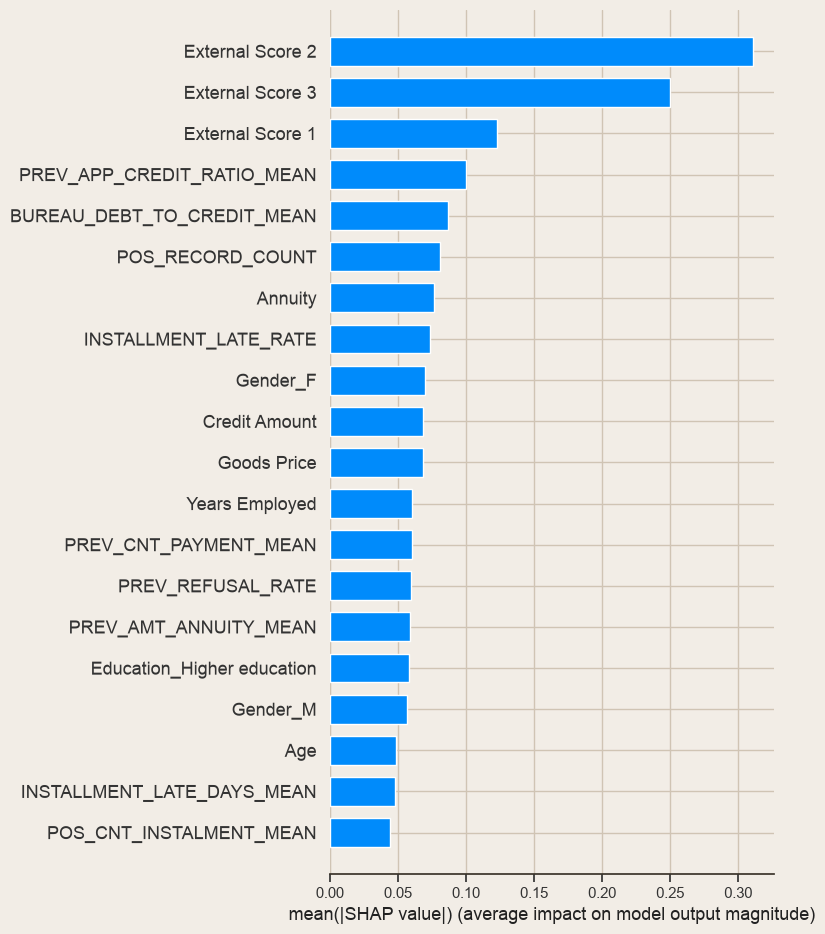

In [38]:
shap.summary_plot(shap_values, X_sample, feature_names=feature_names, plot_type="bar", show=False)
plt.tight_layout()
plt.show()

## 1.5 Choosing a cutoff

The reports above used a cutoff of 0.5, which means little when only 8% of applicants miss
a payment. This finds the cutoff with the best F1, the balance of precision and recall.

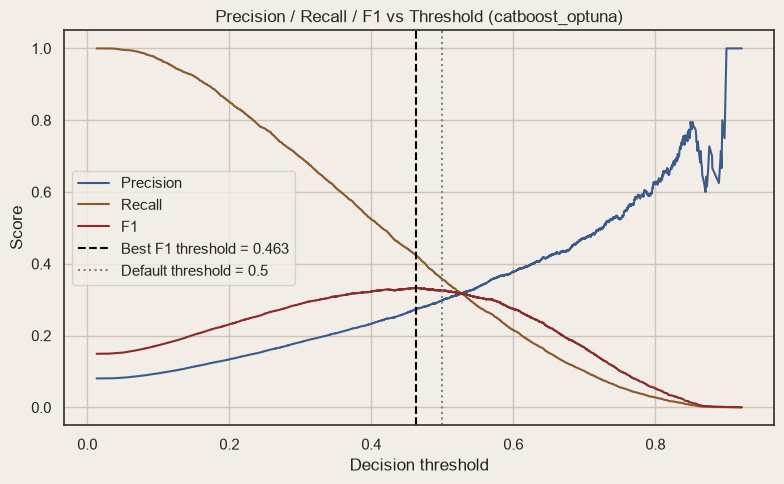

Best F1 threshold: 0.463 (F1 = 0.333)


In [39]:
def best_f1_threshold(y_true, proba):
    """The cutoff with the highest F1, and that F1."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    i = f1[:-1].argmax()
    return float(thresholds[i]), float(f1[i])


y_proba_best = models[best_model_name].predict_proba(X_test)[:, 1]
best_threshold, best_f1 = best_f1_threshold(y_test, y_proba_best)

precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba_best)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-12)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label="Precision", color=earth_palette[2])
plt.plot(thresholds, recalls[:-1], label="Recall", color=earth_palette[1])
plt.plot(thresholds, f1_scores[:-1], label="F1", color=earth_palette[4])
plt.axvline(best_threshold, color="black", linestyle="--", label=f"Best F1 threshold = {best_threshold:.3f}")
plt.axvline(0.5, color="gray", linestyle=":", label="Default threshold = 0.5")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title(f"Precision / Recall / F1 vs Threshold ({best_model_name})")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Best F1 threshold: {best_threshold:.3f} (F1 = {best_f1:.3f})")

## 1.6 Probability calibration

A few made-up applications gave a strange result. Even clearly risky ones scored well under
the 0.463 cutoff. That raised a question: do the model's probabilities mean what they say?

In [ ]:
def decile_table(proba, actual):
    """Mean predicted probability against the actual default rate, per tenth of predictions."""
    d = pd.DataFrame({"proba": proba, "actual": actual})
    d["decile"] = pd.qcut(d["proba"], 10, labels=False, duplicates="drop")
    return d.groupby("decile").agg(mean_predicted=("proba", "mean"),
                                   actual_default_rate=("actual", "mean"),
                                   n=("actual", "size")).reset_index()


proba_uncalibrated = models["catboost_optuna"].predict_proba(X_test)[:, 1]

print("=== Raw probability distribution on the real held-out test set ===")
print(f"True base rate (actual default %):     {y_test.mean():.1%}")
print(f"Mean predicted probability:              {proba_uncalibrated.mean():.1%}")
print(f"Median predicted probability:             {np.median(proba_uncalibrated):.1%}")
print(f"90th percentile predicted probability:    {np.percentile(proba_uncalibrated, 90):.1%}")
print(f"99th percentile predicted probability:    {np.percentile(proba_uncalibrated, 99):.1%}")
print()
print(decile_table(proba_uncalibrated, y_test.values).to_string(index=False))

=== Raw probability distribution on the real held-out test set ===
True base rate (actual default %):     8.1%
Mean predicted probability:              25.0%
Median predicted probability:             20.5%
90th percentile predicted probability:    49.5%
99th percentile predicted probability:    74.0%

 decile  mean_predicted  actual_default_rate    n
      0        0.058268             0.010242 6151
      1        0.092745             0.020000 6150
      2        0.121782             0.023089 6150
      3        0.152191             0.027805 6150
      4        0.186487             0.045684 6151
      5        0.226805             0.053171 6150
      6        0.276693             0.072358 6150
      7        0.342481             0.107154 6150
      8        0.435113             0.153171 6150
      9        0.609548             0.294586 6151


They don't. The model predicts 25% on average when 8.1% of applicants miss a payment. The
ranking is fine, since riskier tenths do miss more often, but every number is about three
times too high.

The cause is `scale_pos_weight`. It gives the rare class more weight, which was meant to
help ranking, and it inflates the probabilities as a side effect. Isotonic regression can
map the scores back onto real frequencies without changing the ranking.

In [ ]:
# Isotonic regression fit with internal 5-fold CV, so it calibrates on folds the base
# model never trained on
calibrated_catboost = CalibratedClassifierCV(
    pipeline(catboost_model(**study_catboost.best_params)), method="isotonic", cv=5,
)
calibrated_catboost.fit(X_train, y_train)
proba_calibrated = calibrated_catboost.predict_proba(X_test)[:, 1]

print("=== BEFORE vs AFTER calibration (same held-out test set) ===")
print(f"True base rate:                {y_test.mean():.1%}")
print(f"Mean predicted (uncalibrated): {proba_uncalibrated.mean():.1%}")
print(f"Mean predicted (calibrated):   {proba_calibrated.mean():.1%}")
print(f"AUC uncalibrated: {roc_auc_score(y_test, proba_uncalibrated):.4f}   AUC calibrated: {roc_auc_score(y_test, proba_calibrated):.4f}")
print(f"AP  uncalibrated: {average_precision_score(y_test, proba_uncalibrated):.4f}   AP  calibrated: {average_precision_score(y_test, proba_calibrated):.4f}")
print()
print(decile_table(proba_calibrated, y_test.values).to_string(index=False))

=== BEFORE vs AFTER calibration (same held-out test set) ===
True base rate:                8.1%
Mean predicted (uncalibrated): 25.0%
Mean predicted (calibrated):   8.0%
AUC uncalibrated: 0.7786   AUC calibrated: 0.7783
AP  uncalibrated: 0.2746   AP  calibrated: 0.2733

 decile  mean_predicted  actual_default_rate    n
      0        0.010218             0.010566 6152
      1        0.016776             0.018516 6157
      2        0.024106             0.022262 6199
      3        0.031446             0.031058 6182
      4        0.042639             0.044375 6062
      5        0.056129             0.055772 6150
      6        0.077089             0.069873 6154
      7        0.105946             0.110804 6146
      8        0.152534             0.148172 6155
      9        0.287128             0.296290 6146


In [ ]:
calibrated_threshold, calibrated_f1 = best_f1_threshold(y_test, proba_calibrated)
print(f"New F1-optimal threshold (calibrated): {calibrated_threshold:.4f} (F1={calibrated_f1:.3f})")
print()
print(classification_report(y_test, (proba_calibrated >= calibrated_threshold).astype(int)))

New F1-optimal threshold (calibrated): 0.1647 (F1=0.332)

              precision    recall  f1-score   support

         0.0       0.95      0.90      0.92     56538
         1.0       0.27      0.43      0.33      4965

    accuracy                           0.86     61503
   macro avg       0.61      0.66      0.63     61503
weighted avg       0.89      0.86      0.87     61503



After calibration the average prediction is 8.0% against a real 8.1%, and each tenth lines
up. AUC barely moves (0.7786 to 0.7783) because calibration rescales the scores without
reordering them. The best cutoff moves from 0.463 to 0.165.

This calibrated CatBoost was the first model the site served. Section 2 shows the
calibration step could have been avoided altogether (§2.6).

---

# 2. What improved the model

The first models reached 0.7786. Was the limit the choice of model, or the pipeline around it?

Mostly the pipeline. Rebuilding it one change at a time raised test AUC to 0.7976. Two
changes account for 88% of that gain: fixing early stopping and building better features.

Each step changes one thing and keeps everything else fixed, so the change in score belongs
to that step. The experiments took about ten hours, so the cells below load their saved
results. The scripts that ran them are not part of this notebook. The recipe they arrived
at (features, cross-validation, search, training) runs end to end in 03_train.ipynb.

| file in `results/` | what it holds |
|---|---|
| `ablation.json` | every setup tried, with its cross-validation and test score |
| `blend_existing.json` | the final blend and the weight given to each model |
| `importances.csv` | features ranked by how much the model used them |
| `fairness_and_form.json` | the results for section 3 |

## 2.1 How models are compared

The first models were chosen by their test score. That uses up the test set, and a test
score isn't very precise anyway. With about 5,000 missed payments among 61,502 test rows, a
test AUC is only good to about ±0.004.

So every choice below is made with 5-fold cross-validation on the training split. The test
set is only read to report.

In [40]:
RESULTS = "results"
RES = json.load(open(f"{RESULTS}/ablation.json"))


def auc_se(n_pos, n_neg, auc):
    """Standard error of an AUC (Hanley and McNeil)."""
    q1, q2 = auc / (2 - auc), 2 * auc**2 / (1 + auc)
    var = (auc * (1 - auc) + (n_pos - 1) * (q1 - auc**2) + (n_neg - 1) * (q2 - auc**2)) / (n_pos * n_neg)
    return float(np.sqrt(var))


se = auc_se(n_pos=4965, n_neg=56537, auc=0.797)
print(f"standard error of a test AUC near 0.797: {se:.4f}")

standard error of a test AUC near 0.797: 0.0039


## 2.2 Better features

The first models summarised each history table with a few averages, about 40 columns in
all. The rebuild in `features.py` does three things differently.

- **It splits by loan status.** Active loans show what someone still owes. Closed loans
  show whether they paid. One average over both hides that.
- **It adds time windows.** Late two years ago and clean since is not the same as late last
  quarter. Repayments are summarised over all time, the last two years and the last year.
- **It adds ratios.** A tree splits on one column at a time, so it can't easily work out
  payment ÷ income by itself. Handing it the ratio helps.

In [41]:
# The ten features the model leaned on most (gain = how much each one improved the splits)
imp = pd.read_csv(f"{RESULTS}/importances.csv")
imp.head(10).round(0)

,feature,gain,split
0,EXT_SOURCES_MEAN,592355.0,514.0
1,ORGANIZATION_TYPE,267932.0,4989.0
2,EXT_SOURCES_WEIGHTED,107123.0,260.0
3,EXT_SOURCES_MIN,98161.0,338.0
4,CREDIT_TERM,52730.0,693.0
5,EXT_SOURCES_MAX,45481.0,210.0
6,OCCUPATION_TYPE,38817.0,589.0
7,EXT_SOURCE_2_X_EMPLOYED,33577.0,249.0
8,INS_2Y_DPD_MEAN,32588.0,184.0
9,PREV_DAYS_LAST_DUE_1ST_VERSION_MAX,32556.0,444.0


`EXT_SOURCES_MEAN`, the average of the three bureau scores, is the most important feature
by a factor of two. Averaging three noisy, partly missing scores gives a cleaner signal
than any one of them.

Read `ORGANIZATION_TYPE` with some caution. It has 58 categories, and this kind of ranking
favours columns that offer many ways to split.

## 2.3 One change at a time

Each row changes one thing from the row above it.

In [42]:
LADDER = {
    "B0_notebook_reproduction": "the first LightGBM pipeline, reproduced",
    "A1_native_nan": "let the model handle missing values (no imputing or scaling)",
    "A2_native_categorical": "let the model handle categories (no one-hot)",
    "A3_early_stopping": "early stopping picks the number of trees",
    "A4_full_features": "all 1,480 new features",
    "A4k600_top600_features": "keep the top 600 features",
    "A5_no_reweight": "drop scale_pos_weight",
    "A6_cohort_features": "add cohort and per-loan features",
    "A7_trial26_bestCV": "hyperparameter search on the full data, scored by AUC",
    "A11_cohort_fixed": "fix a naming bug that had dropped 16 cohort features",
}
blend = json.load(open(f"{RESULTS}/blend_existing.json"))

ladder = pd.DataFrame(
    [{"step": step, "CV AUC": RES[key]["cv_auc"], "test AUC": RES[key]["test_auc"]}
     for key, step in LADDER.items()]
    + [{"step": "blend of 11 models", "CV AUC": blend["oof_auc"], "test AUC": blend["test_auc"]}]
)
ladder.insert(2, "change in CV", ladder["CV AUC"].diff())
ladder.round(4)

,step,CV AUC,change in CV,test AUC
0,"the first LightGBM pipeline, reproduced",0.7738,NaN,0.7759
1,let the model handle missing values (no imputi...,0.7751,0.0013,0.7769
2,let the model handle categories (no one-hot),0.7745,-0.0006,0.7766
3,early stopping picks the number of trees,0.7821,0.0076,0.7849
4,"all 1,480 new features",0.7937,0.0116,0.7959
5,keep the top 600 features,0.7942,0.0006,0.7955
6,drop scale_pos_weight,0.7944,0.0001,0.7955
7,add cohort and per-loan features,0.7950,0.0006,0.7964
8,"hyperparameter search on the full data, scored...",0.7970,0.0021,0.7973
9,fix a naming bug that had dropped 16 cohort fe...,0.7968,-0.0002,0.7972


## 2.4 Early stopping was cutting training short

This was the biggest single fix: +0.008 test AUC with no change to the features or the model.

The first LightGBM used 362 trees. That number was tuned on 20,000 rows and then reused on
246,005. When early stopping picks instead, the folds want 1,100 to 2,100 trees. The model
had been stopping at about a quarter of what it needed.

Adding early stopping the obvious way made things worse. LightGBM watches log-loss as well
as the metric you ask for, and it stops when either one stalls. With `scale_pos_weight` set,
log-loss stalls after about 20 trees while AUC keeps improving for thousands more. Every
fold stopped at tree 19 and CV AUC fell to 0.747. Two settings fix it:

```python
LGBMClassifier(objective="binary", metric="auc", ...)
early_stopping(200, first_metric_only=True)
```

## 2.5 Most of the extra features do nothing

Going from 164 columns to 1,480 was worth +0.012 CV AUC. But the top 300 do as well as all
1,480. The three rows below differ by less than the folds differ from each other (the last
column), so the extra columns are near-copies that cost training time and add nothing.

In [43]:
sweep = {"top 300": "A4k300_top300_features", "top 600": "A4k600_top600_features",
         "all 1,480": "A4_full_features"}
pd.DataFrame([{"features": name, "CV AUC": RES[key]["cv_auc"], "test AUC": RES[key]["test_auc"],
               "spread between folds": RES[key]["cv_fold_std"]} for name, key in sweep.items()]).round(4)

,features,CV AUC,test AUC,spread between folds
0,top 300,0.7935,0.7949,0.0015
1,top 600,0.7942,0.7955,0.0017
2,"all 1,480",0.7937,0.7959,0.0013


## 2.6 Class weighting wasn't worth it

Dropping `scale_pos_weight` changed CV AUC by +0.0002, which is nothing. AUC only measures
ranking, and the extra weight doesn't improve ranking. What it did do was inflate the
probabilities, which is why §1.6 needed a calibration step. Without the weight the
probabilities come out right and no calibration is needed.

## 2.7 Tuning at the right scale

The first search tuned on 20,000 rows and scored by average precision. Then the model was
refit on 246,005 rows and judged by AUC. The new search uses the full training split, scores
by AUC, and leaves the number of trees to early stopping.

In [44]:
best = json.load(open(f"{RESULTS}/A7_trial26_wrapped.json"))["params"]
first = {"num_leaves": 37, "max_depth": 10, "min_child_samples": 52, "colsample_bytree": 0.739,
         "learning_rate": 0.0116, "trees": 362}  # the LightGBM setting from section 1.2
new = {**{k: best[k] for k in first if k in best}, "trees": int(np.mean(RES["A7_trial26_bestCV"]["best_iters"]))}
pd.DataFrame({"first search": first, "new search": new}).round(4)

,first search,new search
num_leaves,37.0000,29.0000
max_depth,10.0000,8.0000
min_child_samples,52.0000,187.0000
colsample_bytree,0.7390,0.1503
learning_rate,0.0116,0.0120
trees,362.0000,3222.0000


The tuned model has a different shape: many small trees that each see about 15% of the
features (`colsample_bytree` 0.15, against 0.74 before). That fits §2.5, since most features
are near-copies of each other.

To save time, trials were ranked on a single 25% holdout and the best few were re-scored
with 5-fold cross-validation. The two rankings disagreed about the winner, so the
cross-validation result was used.

## 2.8 Blending barely helped

Blending several models is the usual next step. Here it added almost nothing.

| attempt | change in test AUC |
|---|---|
| blend 9 LightGBM variants | −0.0001 |
| add XGBoost and CatBoost | +0.0003 |
| tune the XGBoost properly | 0.0000 |
| average 4 seeds of the tuned LightGBM | 0.0000 |

All of these models see the same features and lean on the same bureau scores, so they get
the same applicants wrong and averaging cancels very little. A single tuned LightGBM
(0.7973) is within 0.0003 of the best blend (0.7976), and far simpler to run and explain.

## 2.9 What it adds up to

1. **Early stopping was the biggest bug** (+0.008). LightGBM has to be told to watch AUC only.
2. **Better features were the biggest win** (+0.011), but about 300 of them are enough.
3. **Class weighting added nothing** and broke the probabilities.
4. **Tune on the full data, for the metric you report.**
5. **Blending added almost nothing.** One tuned LightGBM is within 0.0003 of the blend.
6. **Choose with cross-validation.** A test score here is only good to about ±0.004.
7. **A naming bug that dropped 16 cohort features cost nothing measurable.** The lost
   features were near-copies of ones that survived.

**Final test AUC: 0.7976**, up from 0.7786 with the first models. That is the 11-model
blend. The single model scores 0.7973. The target was 0.80 and it was not reached. The gap
(0.0024) is smaller than the test set's standard error (0.0039), so the two can't be told
apart on this data, but 0.7976 is the number to report.

---

# 3. Fairness, and what the form can see

Section 2 scores the model with each applicant's full credit history in front of it. The
website doesn't have that. A preapproval form only knows what the applicant types in. And
two things the form used to ask, sex and marital status, can't be used by US lenders at all
(the Equal Credit Opportunity Act).

Three questions:

1. What does leaving out sex and marital status cost? (§3.1)
2. How well does the full-history model do on form answers alone? (§3.2)
3. Does a model trained only on form answers do better? (§3.3)

The four models take about 15 minutes to fit, so their results are saved. Set
`RUN_FAIRNESS = True` to fit them again. Each model is fit once, so differences smaller
than about 0.002 are noise.

In [45]:
RUN_FAIRNESS = False
FAIRNESS_PATH = f"{RESULTS}/fairness_and_form.json"

if RUN_FAIRNESS:
    from lightgbm import early_stopping, log_evaluation
    from sklearn.metrics import brier_score_loss

    # The cutoff the full-history model was served with (out-of-fold F1-optimal). Every
    # model here is judged at the same cutoff so approval rates compare like for like.
    CUTOFF = 0.1665351755507329
    HISTORY = ("BURO_", "BB_", "PREV_", "POS_", "INS_", "CC_", "INSL_")

    Xa, ya = features.load_matrix()
    Xa_train, Xa_test, ya_train, ya_test = train_test_split(Xa, ya, test_size=0.2, random_state=42, stratify=ya)
    del Xa, ya
    # The 693 features of the full-history model: the top 600 by gain plus every cohort and
    # per-loan feature (§2.5)
    FEATS = [c for c in json.load(open(f"{RESULTS}/features_top600.json")) if c in Xa_train.columns]
    FEATS += [c for c in features.extra_columns() if c in Xa_train.columns and c not in set(FEATS)]
    Xa_train, Xa_test = Xa_train[FEATS], Xa_test[FEATS]
    actual, sex = ya_test.to_numpy(), Xa_test["CODE_GENDER"].astype(str).to_numpy()

    def is_protected(col):
        return "GENDER" in col or "FAMILY_STATUS" in col

    FORM = features.form_feature_columns(FEATS, include_protected=True)
    feature_sets = {
        "baseline": FEATS,
        "without sex and marital status": [c for c in FEATS if not is_protected(c)],
        "form-only": FORM,
        "form-only, without sex and marital status": features.form_feature_columns(FEATS),
    }

    def keep_only(X, keep):
        """Blank every column not in `keep`, keeping categorical dtypes and their levels."""
        out, keep = X.copy(), set(keep)
        for c in out.columns:
            if c not in keep:
                out[c] = (pd.Categorical([np.nan] * len(out), categories=out[c].cat.categories)
                          if isinstance(out[c].dtype, pd.CategoricalDtype) else np.nan)
        return out

    # Three ways of scoring the test set: everything, credit-history tables blanked (an
    # earlier estimate of the site's accuracy), and only what a filled-in form supplies.
    views = {"full history": Xa_test,
             "history blanked": keep_only(Xa_test, [c for c in FEATS if not c.startswith(HISTORY)]),
             "true form": keep_only(Xa_test, FORM)}
    params = json.load(open(f"{RESULTS}/A7_trial26_wrapped.json"))["params"]

    def fit(cols):
        """Early stopping on a stratified fifth sizes the model, then it is refit on all of the
        training split with that many trees."""
        base = dict(objective="binary", metric="auc", verbosity=-1, n_jobs=-1, random_state=42)
        X_fit, X_val, y_fit, y_val = train_test_split(Xa_train[cols], ya_train, test_size=0.2,
                                                      random_state=42, stratify=ya_train)
        probe = LGBMClassifier(**base, **params, n_estimators=20_000)
        probe.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], eval_metric="auc",
                  callbacks=[early_stopping(200, first_metric_only=True, verbose=False), log_evaluation(0)])
        model = LGBMClassifier(**base, **params, n_estimators=max(int(probe.best_iteration_), 50))
        return model.fit(Xa_train[cols], ya_train)

    def summarise(p):
        declined = p >= CUTOFF
        approval = {s: float((~declined)[sex == s].mean()) for s in ("F", "M")}
        return {"auc": roc_auc_score(actual, p), "avg_precision": average_precision_score(actual, p),
                "brier": brier_score_loss(actual, p), "mean_predicted": float(p.mean()),
                "base_rate": float(actual.mean()), "decline_rate": float(declined.mean()),
                "defaults_caught": float(actual[declined].sum() / actual.sum()),
                "approval_by_gender": {**approval, "ratio_M_to_F": approval["M"] / approval["F"]}}

    def by_decile(p):
        d = pd.DataFrame({"predicted": p, "actual": actual})
        d["tenth"] = pd.qcut(d["predicted"].rank(method="first"), 10, labels=False) + 1
        return (d.groupby("tenth").agg(predicted=("predicted", "mean"), actual=("actual", "mean"))
                .round(4).reset_index().to_dict("records"))

    results = {"cutoff": CUTOFF, "n_features": len(FEATS), "form_columns": FORM,
               "protected_columns": [c for c in FEATS if is_protected(c)],
               "models": {}, "calibration_true_form": {}}
    declined_full = {}
    for name, cols in feature_sets.items():
        model = fit(cols)
        results["models"][name] = {}
        for view, X_view in views.items():
            if name.startswith("form-only") and view != "true form":
                continue  # a form-only model never sees anything but the form
            p = model.predict_proba(X_view[cols])[:, 1]
            results["models"][name][view] = summarise(p)
            if view == "true form":
                results["calibration_true_form"][name] = by_decile(p)
            if view == "full history":
                declined_full[name] = p >= CUTOFF
        print(f"fitted: {name}")
    results["decisions_changed_by_dropping_protected"] = float(
        (declined_full["baseline"] != declined_full["without sex and marital status"]).mean())
    with open(FAIRNESS_PATH, "w") as f:
        json.dump(results, f, indent=2)

In [46]:
FAIR = json.load(open(FAIRNESS_PATH))
M = FAIR["models"]
print(f"{FAIR['n_features']} features in the full-history model; {len(FAIR['protected_columns'])} protected; "
      f"a fully answered form supplies {len(FAIR['form_columns'])}")
print(f"every model judged at the cutoff {FAIR['cutoff']:.4f}")

693 features in the full-history model; 18 protected; a fully answered form supplies 117
every model judged at the cutoff 0.1665


## 3.1 Leaving out sex and marital status

Does the model need them?

In [47]:
def approvals(model, view="full history"):
    m = M[model][view]
    by_sex = m["approval_by_gender"]
    return {"test AUC": m["auc"], "women approved": by_sex["F"], "men approved": by_sex["M"],
            "men's rate / women's": by_sex["ratio_M_to_F"]}


display(pd.DataFrame({name: approvals(name) for name in ("baseline", "without sex and marital status")}).T.round(4))
cost = M["baseline"]["full history"]["auc"] - M["without sex and marital status"]["full history"]["auc"]
print(f"AUC cost of leaving them out: {cost:.4f}  (standard error of a test AUC: {se:.4f})")
print(f"approve/decline decisions that change: {FAIR['decisions_changed_by_dropping_protected']:.1%}")

,test AUC,women approved,men approved,men's rate / women's
baseline,0.7972,0.9017,0.8188,0.9080
without sex and marital status,0.7950,0.8944,0.8311,0.9292


AUC cost of leaving them out: 0.0021  (standard error of a test AUC: 0.0039)
approve/decline decisions that change: 2.2%


No. Leaving out sex, marital status and the 16 features built from them costs 0.002 AUC,
about half the test set's standard error, and changes 2.2% of decisions.

It does not make outcomes equal. Men are still approved at 0.93 times the rate of women
(0.91 before). Other inputs such as occupation and the bureau scores carry some of the same
signal, and men in this data do miss payments more often. So the accurate claim is that the
model doesn't use sex or marital status, and it still approves men somewhat less often.
03_train.ipynb checks this for the served model.

## 3.2 What the form can see

An earlier estimate of the website's accuracy, 0.760, blanked the credit-history columns
and scored what was left. But what was left still included 62 columns no form asks for, such
as region ratings and building details. Scoring only what a filled-in form supplies gives
the real figure.

In [48]:
views = {"full history": "everything, as trained",
         "history blanked": "credit history blanked (earlier estimate)",
         "true form": "only what a form supplies"}
display(pd.DataFrame({label: {"test AUC": M["baseline"][view]["auc"],
                              "average prediction": M["baseline"][view]["mean_predicted"],
                              "share declined": M["baseline"][view]["decline_rate"]}
                      for view, label in views.items()}).T.round(4))
print(f"actual rate of early missed payments: {M['baseline']['true form']['base_rate']:.2%}")

,test AUC,average prediction,share declined
"everything, as trained",0.7972,0.0789,0.1265
credit history blanked (earlier estimate),0.7598,0.0914,0.1517
only what a form supplies,0.7486,0.0984,0.1641


actual rate of early missed payments: 8.07%


On form answers the full-history model scores 0.749, not 0.760. Its probabilities are also
too high: 9.8% predicted on average against a real 8.1%, so it declines 16% of applicants
instead of 13%.

## 3.3 A model trained on form answers

The fix is to train the model on what it will actually be given.

,test AUC,average prediction,share declined,men's approval / women's
full-history model,0.7486,0.0984,0.1641,0.8476
form-only model,0.7674,0.0803,0.1206,0.8976
"form-only, without sex and marital status",0.7666,0.0803,0.1192,0.9157


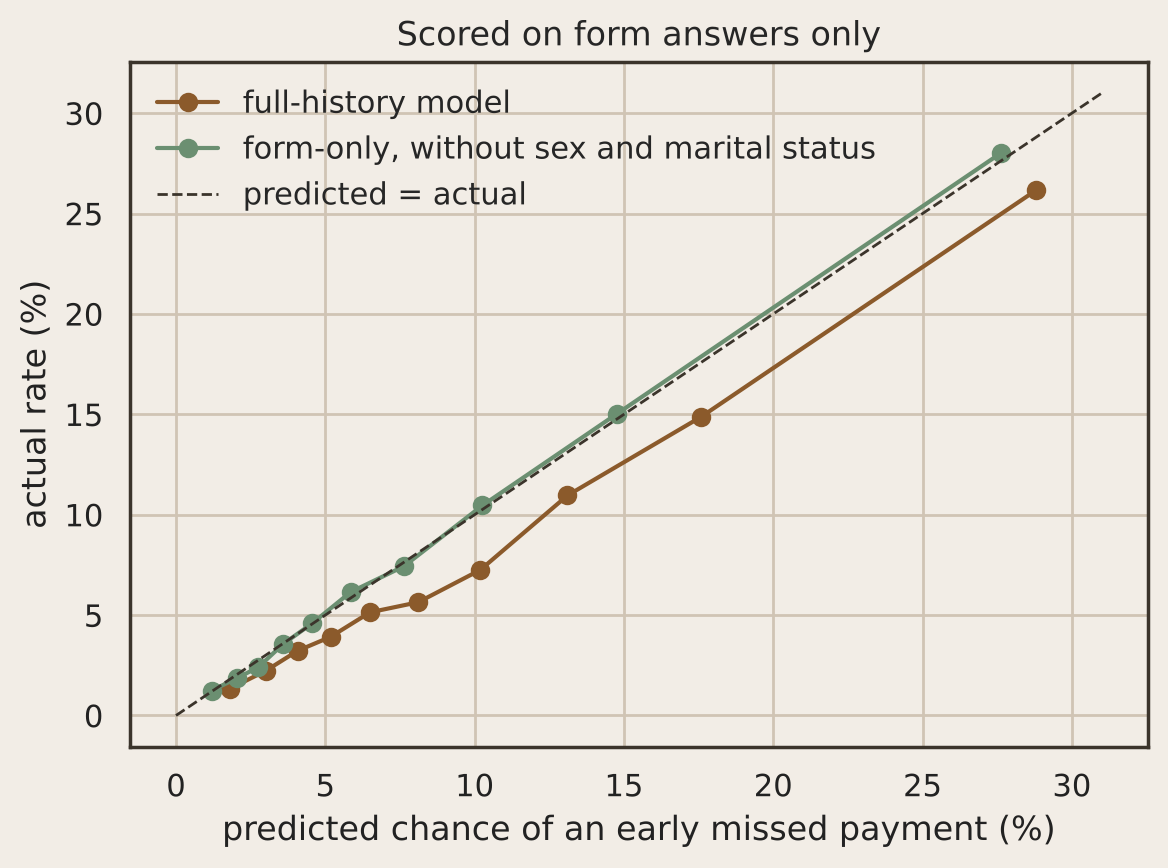

In [49]:
rows = {"full-history model": "baseline", "form-only model": "form-only",
        "form-only, without sex and marital status": "form-only, without sex and marital status"}
on_form = {label: M[name]["true form"] for label, name in rows.items()}
display(pd.DataFrame({label: {"test AUC": m["auc"], "average prediction": m["mean_predicted"],
                              "share declined": m["decline_rate"],
                              "men's approval / women's": m["approval_by_gender"]["ratio_M_to_F"]}
                      for label, m in on_form.items()}).T.round(4))

# Predicted against actual, for each tenth of applicants. On the dashed line the two agree.
fig, ax = plt.subplots(figsize=(6, 4.5))
for label, color in (("full-history model", earth_palette[1]),
                     ("form-only, without sex and marital status", earth_palette[0])):
    tenths = pd.DataFrame(FAIR["calibration_true_form"][rows[label]])
    ax.plot(tenths["predicted"] * 100, tenths["actual"] * 100, marker="o", color=color, label=label)
ax.plot([0, 31], [0, 31], ls="--", lw=1, color="#3b342b", label="predicted = actual")
ax.set(xlabel="predicted chance of an early missed payment (%)",
       ylabel="actual rate (%)", title="Scored on form answers only")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Trained on form answers, the model scores 0.767 instead of 0.749, and its probabilities
line up again (8.0% predicted against 8.1% actual). Leaving out sex and marital status costs
0.0008.

So the website serves the last row: form answers only, no sex or marital status.
03_train.ipynb builds it. The 0.7976 from section 2 is what the full data can support, and
0.767 is what a preapproval form can deliver.